# 指標の分布の図（2026-10-15）

今井先生との 9/28 の打ち合わせを受けたメール（9/29）「今回のエクササイズではとりあえず指標の分布プロットを追加。その他の分析はデータ拡充・他指標などの目処がたってから」への対応。

報告資料（`docs/slides/toyota_novelty_progress.pptx`、2026-09-28）は順位の中央値を表で示していた。ここでは**資料の表と同じ行・列の並び**で、各マスに中央値の代わりに順位の分布を描く。新しい計算はしない。

| 図 | 対応する資料のページ | 行 | 列 |
|---|---|---|---|
| 図1 `fig_slide7_rank_by_condition.png` | 7ページ「一般論文との比較（トヨタ系列全体）」 | 揃えた条件（4段階） | 指標（4つ） |
| 図2 `fig_slide8_rank_by_org.png` | 8ページ「一般論文との比較（組織別）」 | 組織（4つ＋全体） | 指標（4つ） |
| 図3 `fig_slide11_disruption_by_team.png` | 11ページ「補足：チーム規模別の破壊性」 | チーム規模（4区分） | 揃えた条件（4段階） |
| 補足 `fig_supp_values.png` | （資料にない）値そのものの分布 | — | — |

- 入力: `data/derived/analysis/paper_analysis.csv`、`paper_percentiles.csv`、`baseline_sample.csv`（資料の数字を出した `docs/slides/make_numbers_progress_2026-09.py` と同じ表）
- 対象: 2000年以降の論文（資料と同じ前提）
- 出力: `figures/novelty_distributions/`。図はスライド（16:9）にそのまま貼れる大きさ
- `rank_summary.csv` に各マスの件数・中央値・上下4分の1の割合を書き出す
- 最後のセルで、図に書いた中央値が資料の表（`docs/slides/numbers_progress_2026-09.json`）と一致することを確かめる

注: リポジトリ内のデータでは組織名を「トヨタ自動車未来創成センター」と書いているが、正式名称は「未来創生センター」。図では正式名称を使う。


In [1]:
from pathlib import Path
import json

import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from IPython.display import Image, display

# リポジトリの最上位（AGENTS.md がある場所）を探す
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "AGENTS.md").exists())
DD = ROOT / "data" / "derived" / "analysis"
FIG = ROOT / "figures" / "novelty_distributions"
FIG.mkdir(parents=True, exist_ok=True)

YEAR_FROM = 2000  # 資料と同じ前提

# データ内の組織名 → 図に書く名前（正式名称）。順序は資料8ページの表と同じ
ORGS = {"豊田中央研究所": "豊田中央研究所",
        "トヨタ自動車未来創成センター": "未来創生センター",
        "AISIN IMRA(日本・aisin.com)": "AISIN IMRA（日本）",
        "AISIN IMRA(米国・imra.com)": "AISIN IMRA（米国）"}

# 指標: 列の接頭辞 → (図に書く名前, 向きの説明, 順位を反転するか)。順序は資料の表と同じ
# 非慣習性は SciSciNet の値が低いほど珍しい組み合わせを含むので、順位は 100 から引いて
# 「高いほど珍しい」に向きを揃える（資料と同じ扱い）
METRICS = {"ss_novelty": ("非慣習性", "高いほど珍しい組み合わせ", True),
           "ss_conventionality": ("定石らしさ", "高いほど定石の組み合わせ", False),
           "ss_disruption": ("破壊性", "高いほど流れを断ち切る", False),
           "ss_c10": ("10年被引用", "高いほど多く引用", False)}

# 揃えた条件: paper_percentiles.csv の列の接尾辞 → 図に書く名前。順序は資料7ページ・11ページの表と同じ
STAGES = {"": "分野・年のみ", "_ref": "分野・年＋参考文献数", "_team": "分野・年＋チーム規模", "_ref_team": "分野・年＋両方"}

a = pd.read_csv(DD / "paper_analysis.csv")      # 論文1件1行。SciSciNet の値と説明変数
p = pd.read_csv(DD / "paper_percentiles.csv")   # 一般論文の中での順位（0〜100）。n_refs は参考文献数
smp = pd.read_csv(DD / "baseline_sample.csv")   # 比較相手の一般論文（分野・年ごとに無作為に最大3,000件）
N = json.loads((ROOT / "docs" / "slides" / "numbers_progress_2026-09.json").read_text())  # 資料の表の数字

# 資料の数字を出したスクリプトと同じ手順で表を作る
d = p.merge(a[["paper_uid", "source_org", "ss_team_size",
               "ss_novelty", "ss_conventionality", "ss_disruption", "ss_c10"]], on="paper_uid", how="left")
d = d[d["year"] >= YEAR_FROM].copy()
cells = d[["field_id", "year"]].drop_duplicates()
base = smp.merge(cells, on=["field_id", "year"])  # トヨタの論文と同じ分野・年の一般論文
print(len(d), "件（トヨタ、2000年以降）", len(base), "件（比較相手）", len(cells), "通りの分野・年")

# SciSciNet の zスコアには無限大（inf）の論文がある。値そのものの図では欠損として扱う（順位の列には影響しない）
SS_COLS = ["ss_novelty", "ss_conventionality", "ss_disruption", "ss_c10"]
for name, df in [("トヨタ", d), ("比較相手", base)]:
    n_inf = {c: int(np.isinf(df[c]).sum()) for c in SS_COLS}
    print(name, "の無限大の件数:", n_inf)
    df[SS_COLS] = df[SS_COLS].replace([np.inf, -np.inf], np.nan)

plt.rcParams.update({"font.family": "Hiragino Sans", "font.size": 10})
GRAY, INK, DIM = "#a6a6a6", "#222222", "#777777"


624 件（トヨタ、2000年以降） 432000 件（比較相手） 144 通りの分野・年
トヨタ の無限大の件数: {'ss_novelty': 0, 'ss_conventionality': 0, 'ss_disruption': 0, 'ss_c10': 0}
比較相手 の無限大の件数: {'ss_novelty': 395, 'ss_conventionality': 2232, 'ss_disruption': 0, 'ss_c10': 0}


## 順位の分布を、資料の表と同じ並びで描く

順位は、その論文と同じ分野・同じ年（条件によってはさらに参考文献数・著者数も近い）の一般論文の中で、何パーセントの位置にあるかを 0〜100 で表した値（50 が真ん中）。資料と同じ値（`paper_percentiles.csv`）をそのまま使う。

各マスの描き方:

- 順位を幅 20 の5つの区間（0〜20、…、80〜100）に分け、各区間に入る論文の割合を棒で描く
- トヨタの論文が一般論文と同じ分布なら、各区間に 20% ずつ入る。破線がその高さ。棒が破線より高い区間に論文が偏っている
- 縦線と太字の数字は順位の中央値。資料の表に載せた数字と同じ
- 左上の小さい数字は件数（比べる相手が 30 件未満の論文は順位が無いので、条件によって少し減る）


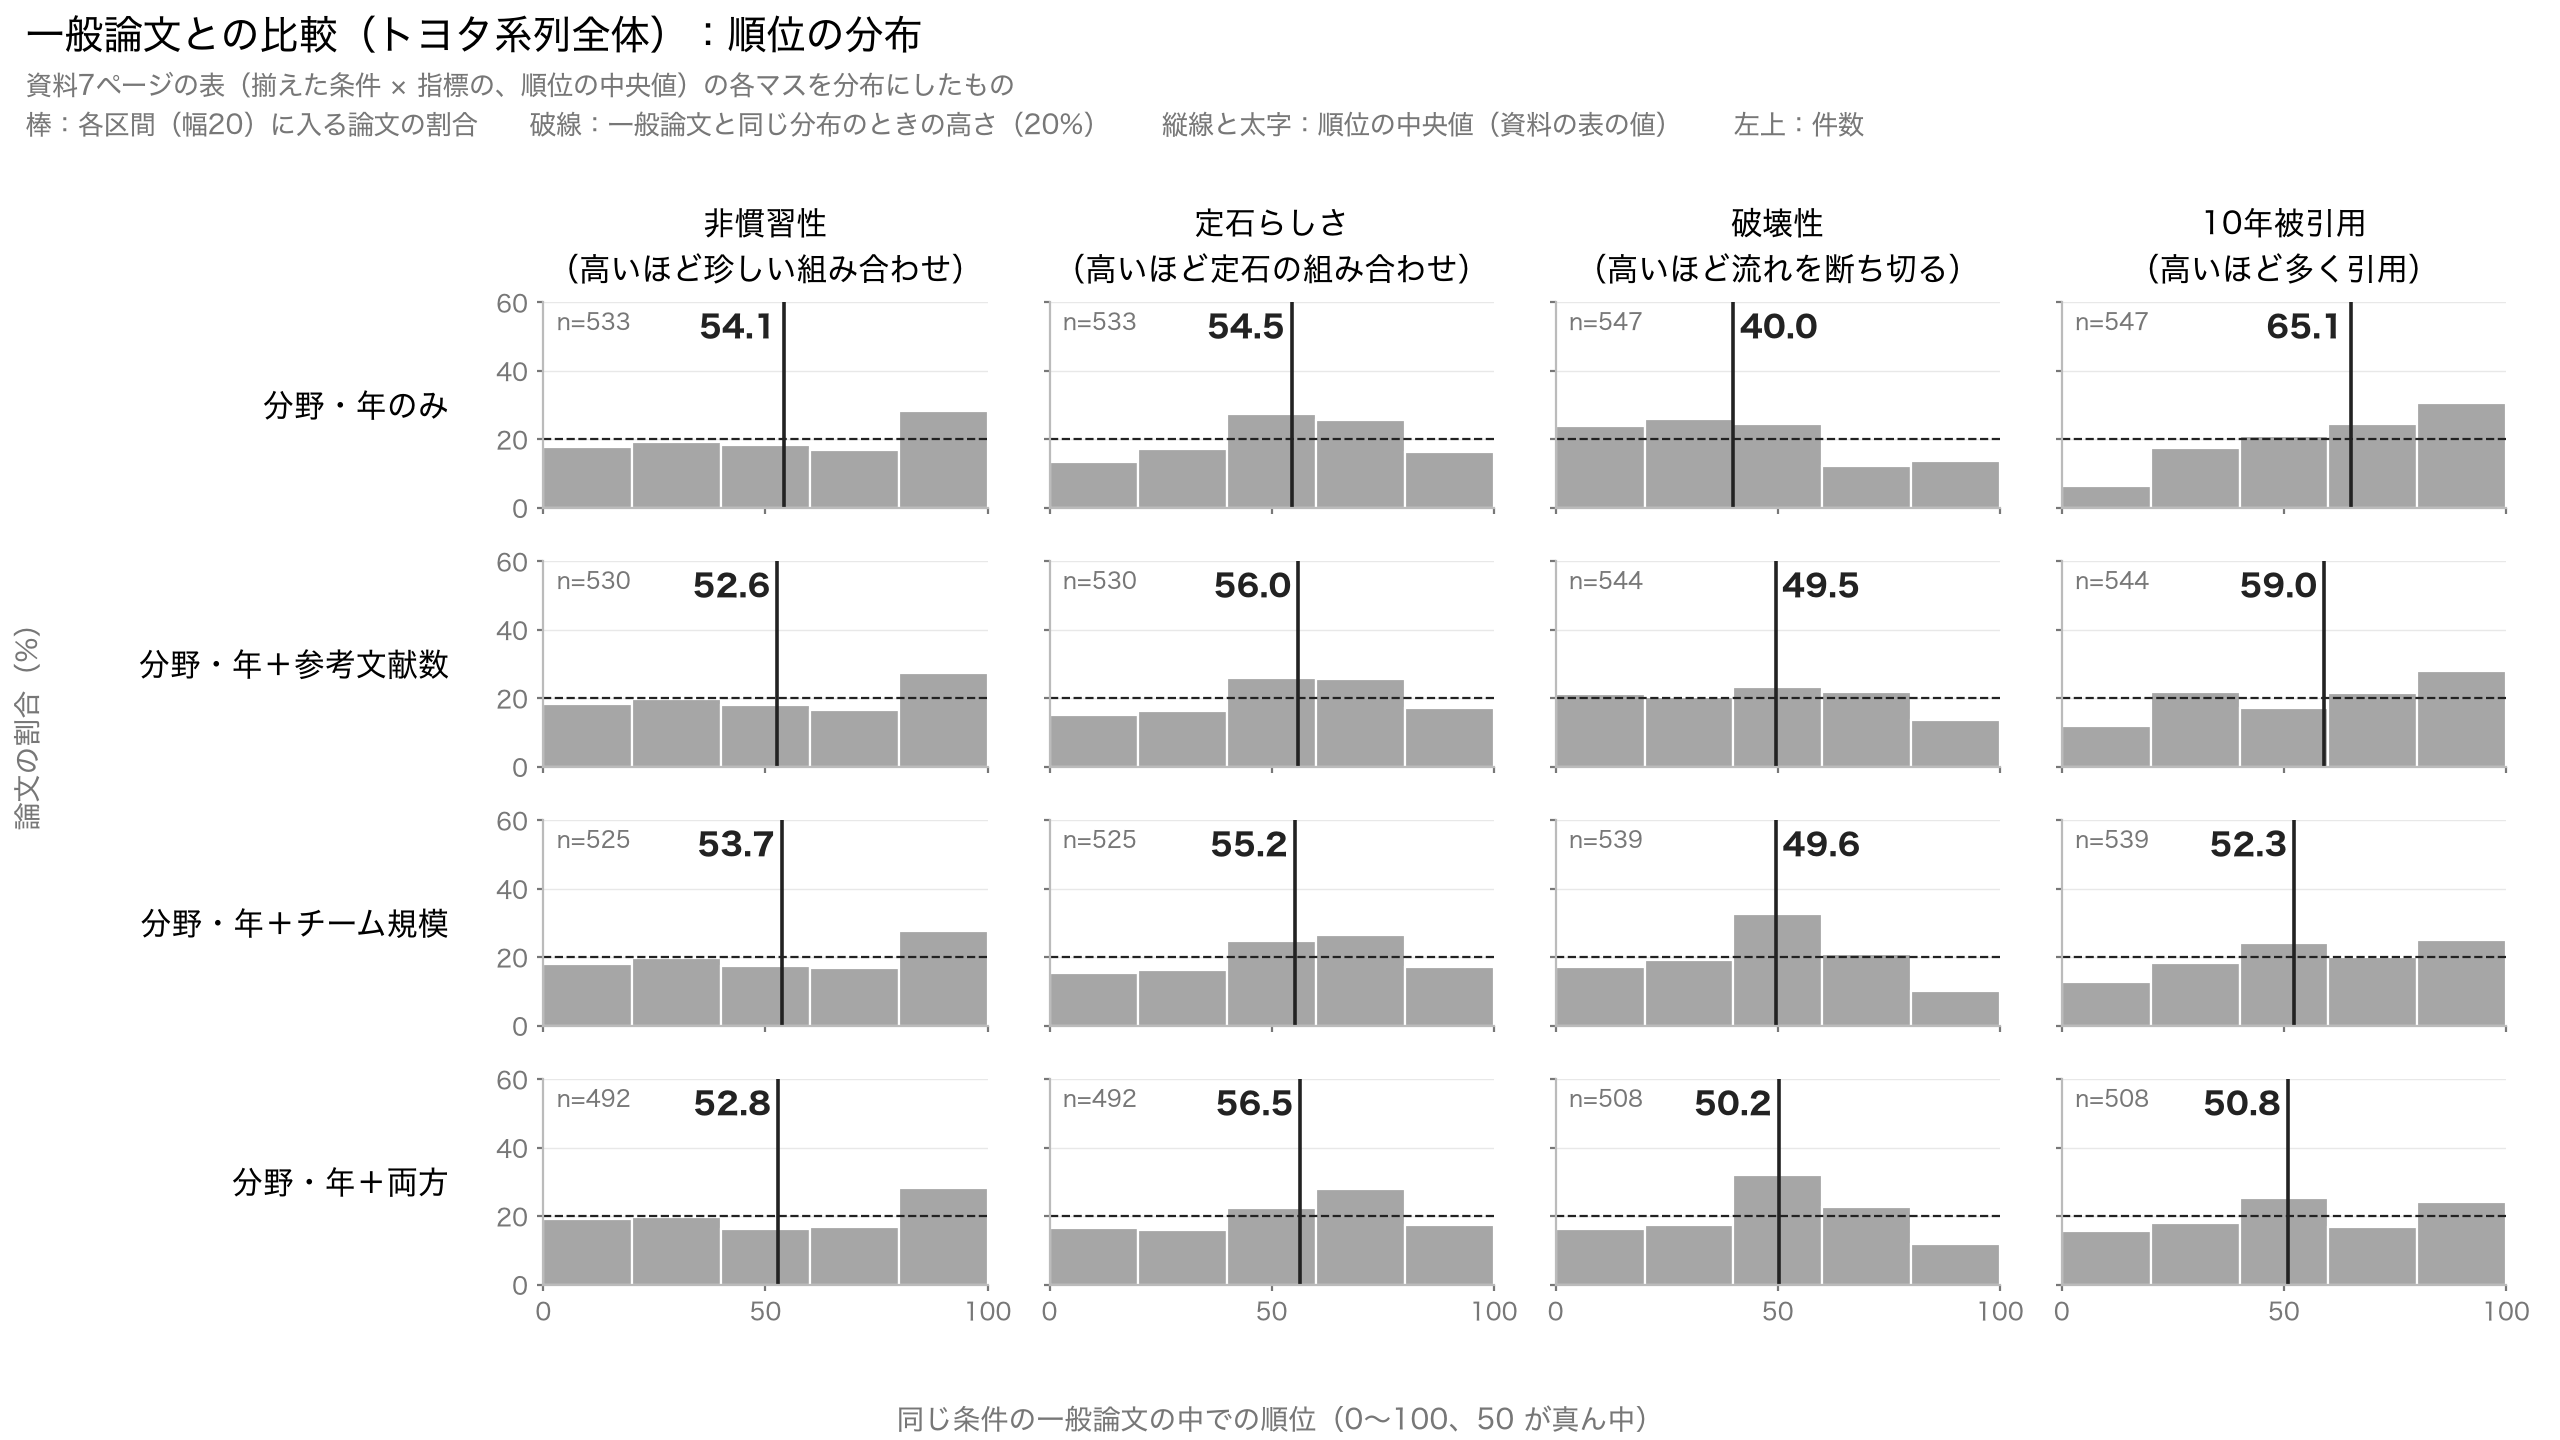

,図,行,列,n,中央値,下位4分の1（25以下）の割合%,上位4分の1（75以上）の割合%
0,図1（資料7ページ）,分野・年のみ,非慣習性 （高いほど珍しい組み合わせ）,533,54.1,20.5,33.0
1,図1（資料7ページ）,分野・年のみ,定石らしさ （高いほど定石の組み合わせ）,533,54.5,18.2,22.0
2,図1（資料7ページ）,分野・年のみ,破壊性 （高いほど流れを断ち切る）,547,40.0,29.1,17.4
3,図1（資料7ページ）,分野・年のみ,10年被引用 （高いほど多く引用）,547,65.1,9.7,36.9
4,図1（資料7ページ）,分野・年＋参考文献数,非慣習性 （高いほど珍しい組み合わせ）,530,52.6,23.2,31.1
5,図1（資料7ページ）,分野・年＋参考文献数,定石らしさ （高いほど定石の組み合わせ）,530,56.0,20.0,23.4
6,図1（資料7ページ）,分野・年＋参考文献数,破壊性 （高いほど流れを断ち切る）,544,49.5,25.4,18.9
7,図1（資料7ページ）,分野・年＋参考文献数,10年被引用 （高いほど多く引用）,544,59.0,17.1,32.7
8,図1（資料7ページ）,分野・年＋チーム規模,非慣習性 （高いほど珍しい組み合わせ）,525,53.7,21.5,33.5
9,図1（資料7ページ）,分野・年＋チーム規模,定石らしさ （高いほど定石の組み合わせ）,525,55.2,19.2,22.9


In [2]:
EDGES = np.arange(0, 101, 20)
YMAX = 60  # 縦軸の上限（%）。最大の区間は AISIN IMRA（米国）の10年被引用の 80〜100 で 50%


def panel(ax, v: pd.Series, show_ylabels: bool, show_xlabels: bool) -> dict:
    # 1マス分。v は向きを揃えた順位（0〜100）
    v = v.dropna()
    share = np.histogram(v, bins=EDGES)[0] / len(v) * 100  # 各区間に入る論文の割合（%）
    ax.bar(EDGES[:-1] + 10, share, width=20, color=GRAY, edgecolor="white", linewidth=0.8)
    ax.axhline(20, color=INK, ls="--", lw=0.8)  # 一般論文と同じ分布なら各区間に 20% ずつ
    med = float(v.median())
    ax.axvline(med, color=INK, lw=1.3)
    # 中央値の数字は縦線のすぐ横。線が右寄りなら左側に、左寄りなら右側に置く
    ax.text(med + (-1.5 if med >= 50 else 1.5), YMAX * 0.96, f"{med:.1f}", ha="right" if med >= 50 else "left",
            va="top", fontsize=11, fontweight="bold", color=INK)
    ax.text(0.03, 0.96, f"n={len(v)}", transform=ax.transAxes, ha="left", va="top", fontsize=8, color=DIM)
    ax.set_xlim(0, 100)
    ax.set_ylim(0, YMAX)
    ax.set_xticks([0, 50, 100])
    ax.set_yticks([0, 20, 40, 60])
    if not show_ylabels:
        ax.set_yticklabels([])
    if not show_xlabels:
        ax.set_xticklabels([])
    ax.tick_params(labelsize=8.5, length=2, colors=DIM)
    ax.grid(axis="y", color="#e8e8e8", lw=0.5)
    ax.set_axisbelow(True)
    for s in ("top", "right"):
        ax.spines[s].set_visible(False)
    for s in ("left", "bottom"):
        ax.spines[s].set_color("#bbbbbb")
    return {"n": int(len(v)), "中央値": round(med, 1),
            "下位4分の1（25以下）の割合%": round(float((v <= 25).mean() * 100), 1),
            "上位4分の1（75以上）の割合%": round(float((v >= 75).mean() * 100), 1)}


def grid(rows: list, cols: list, values, title: str, subtitle: str, fname: str, fig_label: str) -> pd.DataFrame:
    # rows / cols は (キー, 見出し) の並び。values(行キー, 列キー) が順位の Series を返す。
    # 資料の表と同じ並びで、行が表の行、列が表の列になる
    fig, axes = plt.subplots(len(rows), len(cols), figsize=(12.8, 7.2), dpi=200)
    out = []
    for i, (rk, rlab) in enumerate(rows):
        for j, (ck, clab) in enumerate(cols):
            ax = axes[i, j]
            res = panel(ax, values(rk, ck), show_ylabels=(j == 0), show_xlabels=(i == len(rows) - 1))
            if i == 0:
                ax.set_title(clab, fontsize=11, pad=8)
            if j == 0:
                # 行の見出しは横書きで、左の目盛りのさらに左に置く（縦書きだと行どうしで重なる）
                ax.annotate(rlab, xy=(0, 0.5), xycoords="axes fraction", xytext=(-34, 0), textcoords="offset points",
                            ha="right", va="center", fontsize=11)
            out.append({"図": fig_label, "行": rlab, "列": clab.replace("\n", " "), **res})
    fig.suptitle(title, fontsize=14, x=0.01, ha="left", y=0.99)
    fig.text(0.01, 0.955, subtitle, fontsize=9.5, color=DIM, ha="left", va="top", linespacing=1.5)
    fig.supxlabel("同じ条件の一般論文の中での順位（0〜100、50 が真ん中）", fontsize=10, color=DIM, y=0.005)
    fig.supylabel("論文の割合（%）", fontsize=10, color=DIM, x=0.005)
    fig.tight_layout(rect=(0.02, 0.02, 1, 0.93))  # 行の見出しの幅は tight_layout が見込むので、左の余白は小さくてよい
    fig.savefig(FIG / fname, facecolor="white")
    plt.close(fig)
    display(Image(str(FIG / fname), width=1000))
    return pd.DataFrame(out)


SUB = "\n棒：各区間（幅20）に入る論文の割合　　破線：一般論文と同じ分布のときの高さ（20%）　　縦線と太字：順位の中央値（資料の表の値）　　左上：件数"
COLS_METRIC = [(m, f"{lab}\n（{dirn}）") for m, (lab, dirn, _) in METRICS.items()]


def ranks(g: pd.DataFrame, m: str, suffix: str) -> pd.Series:
    v = g[f"{m}_pct{suffix}"]
    return 100 - v if METRICS[m][2] else v


# 図1: 資料7ページ。行 = 揃えた条件、列 = 指標。トヨタ系列全体
summ1 = grid(rows=list(STAGES.items()), cols=COLS_METRIC,
             values=lambda suf, m: ranks(d, m, suf),
             title="一般論文との比較（トヨタ系列全体）：順位の分布",
             subtitle="資料7ページの表（揃えた条件 × 指標の、順位の中央値）の各マスを分布にしたもの" + SUB,
             fname="fig_slide7_rank_by_condition.png", fig_label="図1（資料7ページ）")
summ1


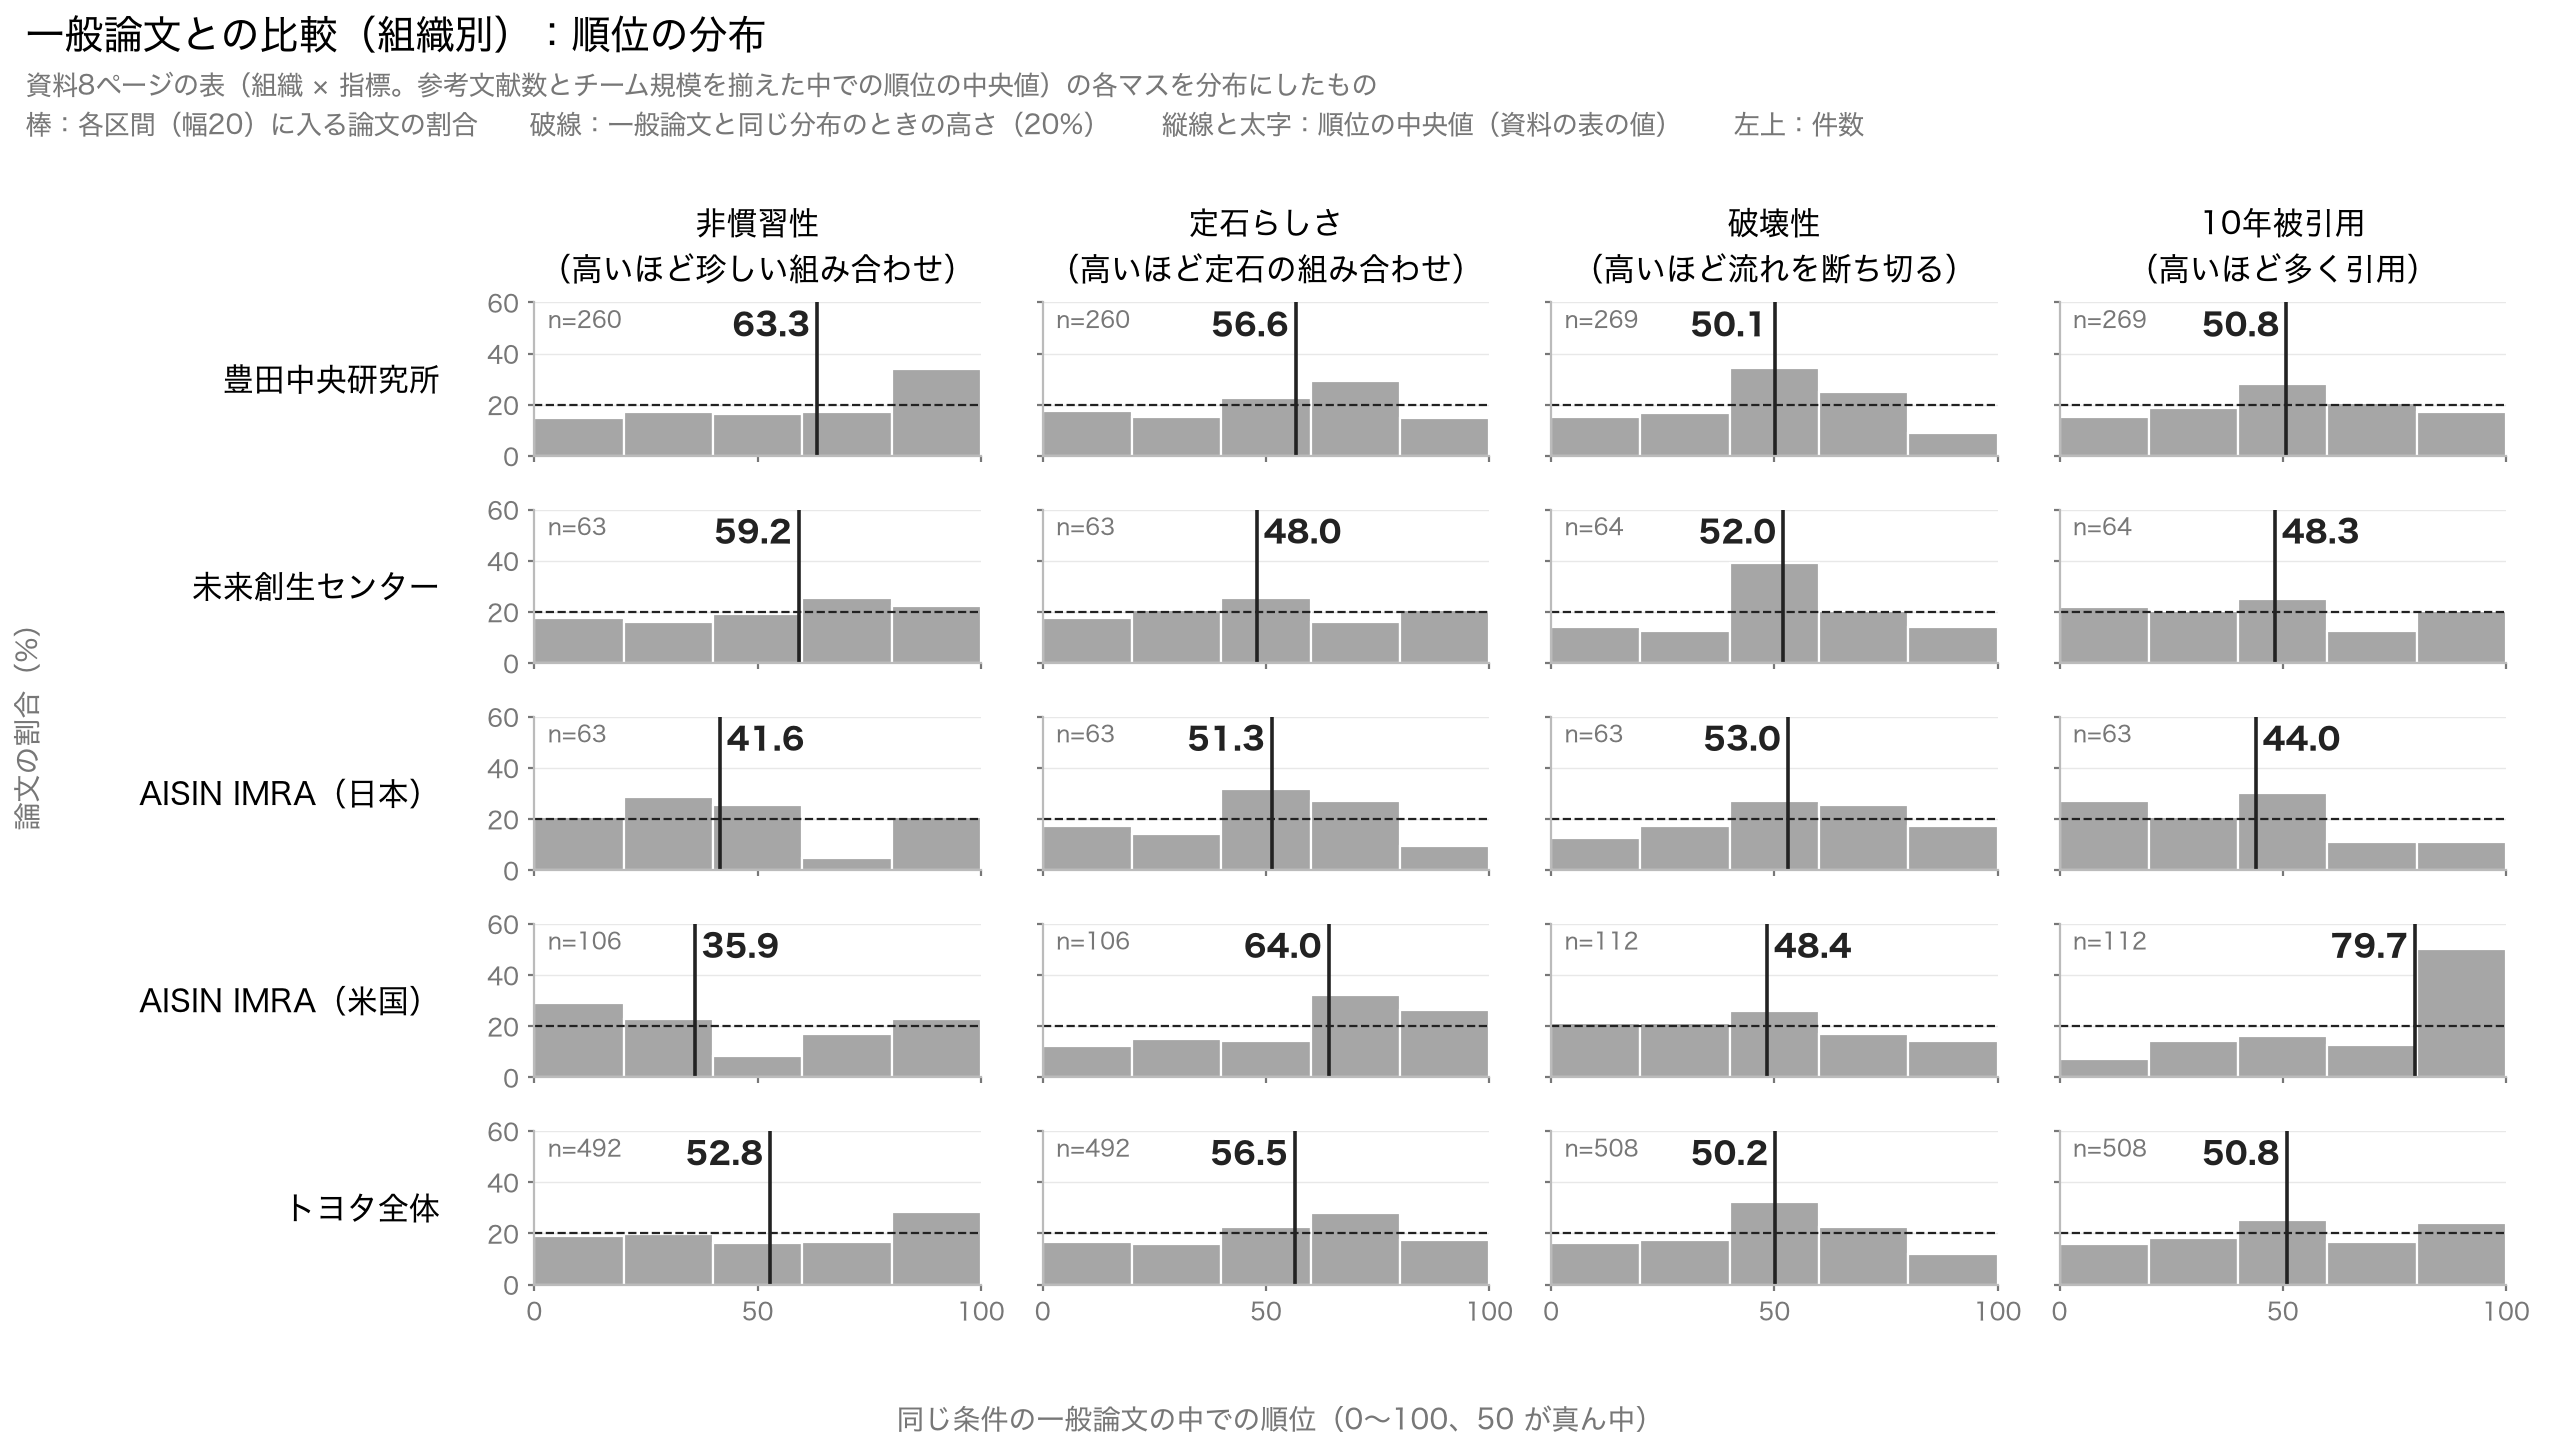

,図,行,列,n,中央値,下位4分の1（25以下）の割合%,上位4分の1（75以上）の割合%
0,図2（資料8ページ）,豊田中央研究所,非慣習性 （高いほど珍しい組み合わせ）,260,63.3,17.7,39.2
1,図2（資料8ページ）,豊田中央研究所,定石らしさ （高いほど定石の組み合わせ）,260,56.6,21.5,24.2
2,図2（資料8ページ）,豊田中央研究所,破壊性 （高いほど流れを断ち切る）,269,50.1,18.6,13.4
3,図2（資料8ページ）,豊田中央研究所,10年被引用 （高いほど多く引用）,269,50.8,21.6,24.2
4,図2（資料8ページ）,未来創生センター,非慣習性 （高いほど珍しい組み合わせ）,63,59.2,22.2,30.2
5,図2（資料8ページ）,未来創生センター,定石らしさ （高いほど定石の組み合わせ）,63,48.0,22.2,25.4
6,図2（資料8ページ）,未来創生センター,破壊性 （高いほど流れを断ち切る）,64,52.0,20.3,20.3
7,図2（資料8ページ）,未来創生センター,10年被引用 （高いほど多く引用）,64,48.3,28.1,21.9
8,図2（資料8ページ）,AISIN IMRA（日本）,非慣習性 （高いほど珍しい組み合わせ）,63,41.6,23.8,22.2
9,図2（資料8ページ）,AISIN IMRA（日本）,定石らしさ （高いほど定石の組み合わせ）,63,51.3,22.2,17.5


In [3]:
# 図2: 資料8ページ。行 = 組織（＋トヨタ全体）、列 = 指標。参考文献数とチーム規模を揃えた順位
rows2 = [(org, lab) for org, lab in ORGS.items()] + [("__all__", "トヨタ全体")]
summ2 = grid(rows=rows2, cols=COLS_METRIC,
             values=lambda org, m: ranks(d if org == "__all__" else d[d["source_org"] == org], m, "_ref_team"),
             title="一般論文との比較（組織別）：順位の分布",
             subtitle="資料8ページの表（組織 × 指標。参考文献数とチーム規模を揃えた中での順位の中央値）の各マスを分布にしたもの" + SUB,
             fname="fig_slide8_rank_by_org.png", fig_label="図2（資料8ページ）")
summ2


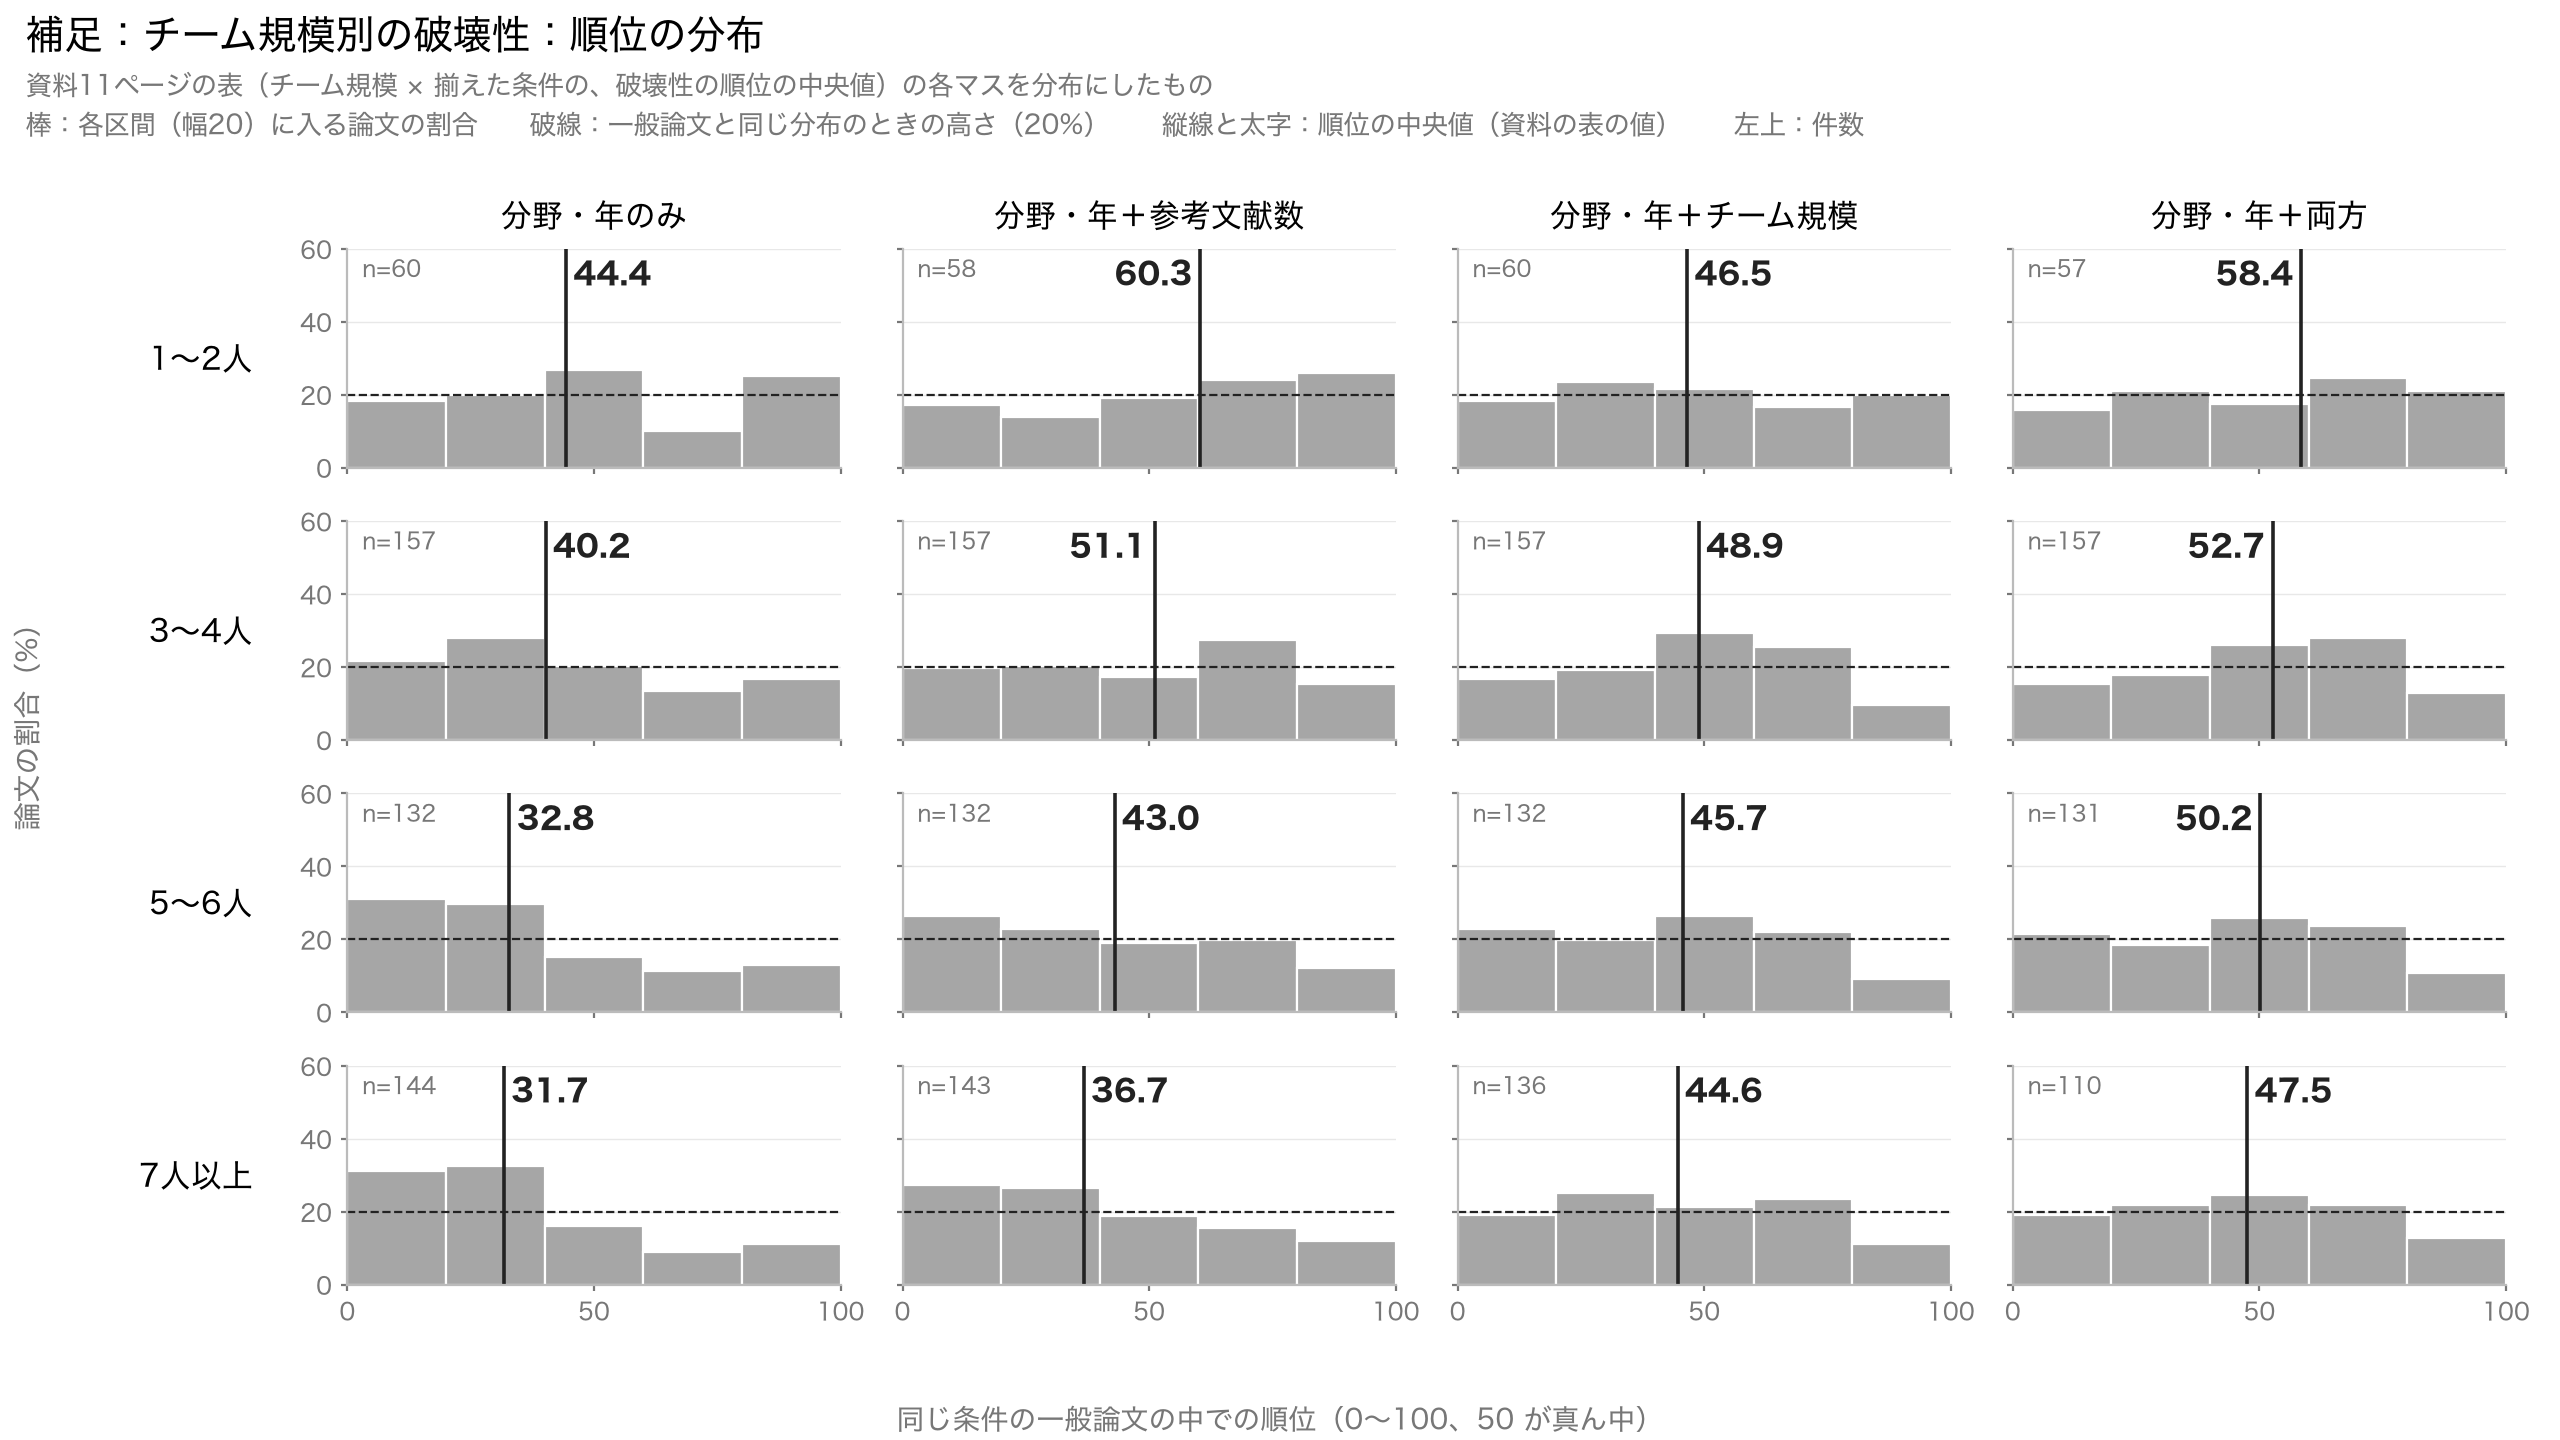

,図,行,列,n,中央値,下位4分の1（25以下）の割合%,上位4分の1（75以上）の割合%
0,図3（資料11ページ）,1〜2人,分野・年のみ,60,44.4,20.0,28.3
1,図3（資料11ページ）,1〜2人,分野・年＋参考文献数,58,60.3,20.7,31.0
2,図3（資料11ページ）,1〜2人,分野・年＋チーム規模,60,46.5,26.7,26.7
3,図3（資料11ページ）,1〜2人,分野・年＋両方,57,58.4,19.3,29.8
4,図3（資料11ページ）,3〜4人,分野・年のみ,157,40.2,26.8,22.9
5,図3（資料11ページ）,3〜4人,分野・年＋参考文献数,157,51.1,21.7,24.8
6,図3（資料11ページ）,3〜4人,分野・年＋チーム規模,157,48.9,19.7,14.0
7,図3（資料11ページ）,3〜4人,分野・年＋両方,157,52.7,18.5,17.2
8,図3（資料11ページ）,5〜6人,分野・年のみ,132,32.8,37.1,15.9
9,図3（資料11ページ）,5〜6人,分野・年＋参考文献数,132,43.0,31.1,18.2


In [4]:
# 図3: 資料11ページ。行 = チーム規模、列 = 揃えた条件。破壊性の順位
# チーム規模の区分は資料と同じ（make_numbers_progress_2026-09.py）。著者数 0 の論文はどの区分にも入らない
team_bins = pd.cut(d["ss_team_size"], [0, 2, 4, 6, 1e9], labels=["1〜2人", "3〜4人", "5〜6人", "7人以上"])
rows3 = [(t, t) for t in team_bins.cat.categories]
summ3 = grid(rows=rows3, cols=list(STAGES.items()),
             values=lambda t, suf: ranks(d[team_bins == t], "ss_disruption", suf),
             title="補足：チーム規模別の破壊性：順位の分布",
             subtitle="資料11ページの表（チーム規模 × 揃えた条件の、破壊性の順位の中央値）の各マスを分布にしたもの" + SUB,
             fname="fig_slide11_disruption_by_team.png", fig_label="図3（資料11ページ）")
summary = pd.concat([summ1, summ2, summ3], ignore_index=True)
summary.to_csv(FIG / "rank_summary.csv", index=False, encoding="utf-8-sig")
summ3


## 補足: 値そのものの分布（トヨタ全体と比較相手）

順位ではなく SciSciNet の値そのものを、トヨタの論文と比較相手の一般論文で重ねて描く。資料には無い図で、値の形（裾の重さ、0 の塊）を見るためのもの。

- **比較相手の重み付け。** 比較相手は分野・年ごとに最大3,000件ずつ引いてあるので、そのまま重ねるとトヨタの論文が1件しかない分野・年も、100件ある分野・年と同じ重さで入る。そこで分野・年ごとに「トヨタの件数 ÷ 比較相手の件数」の重みを付け、分野・年の構成をトヨタの論文と同じにしてから描く。
- **横軸の変換。** zスコアは数千に達する論文があるので、符号を保ったまま対数的に縮める（±10 までは線形に近い）。破壊性は大半が ±0.01 の中に集まるので、同じ縮め方を ±0.001 を基準にして使う。被引用と参考文献数は 1 を足して対数にする。目盛りには元の値を書く。
- **無限大の値。** SciSciNet の zスコアには無限大の論文がある（件数は上のセルの出力）。この図では欠損として扱う。順位は元の表の値をそのまま使っているので影響しない。
- **破壊性の 0。** SciSciNet v2 は引用されていない論文に 0 を入れているとみられる（2026-09-28 のログ）。ちょうど 0 の論文の割合をパネルに書く。
- **著者数の 0。** SciSciNet の著者の記録が欠けている論文（2024年に多い）。直さずそのまま描く（2026-10-14 の判断）。20人以上は 20 にまとめる。
- 縦軸は論文の相対的な多さ（面積が 1 になるようにした密度）。目盛りの数字に意味がないので消してある。


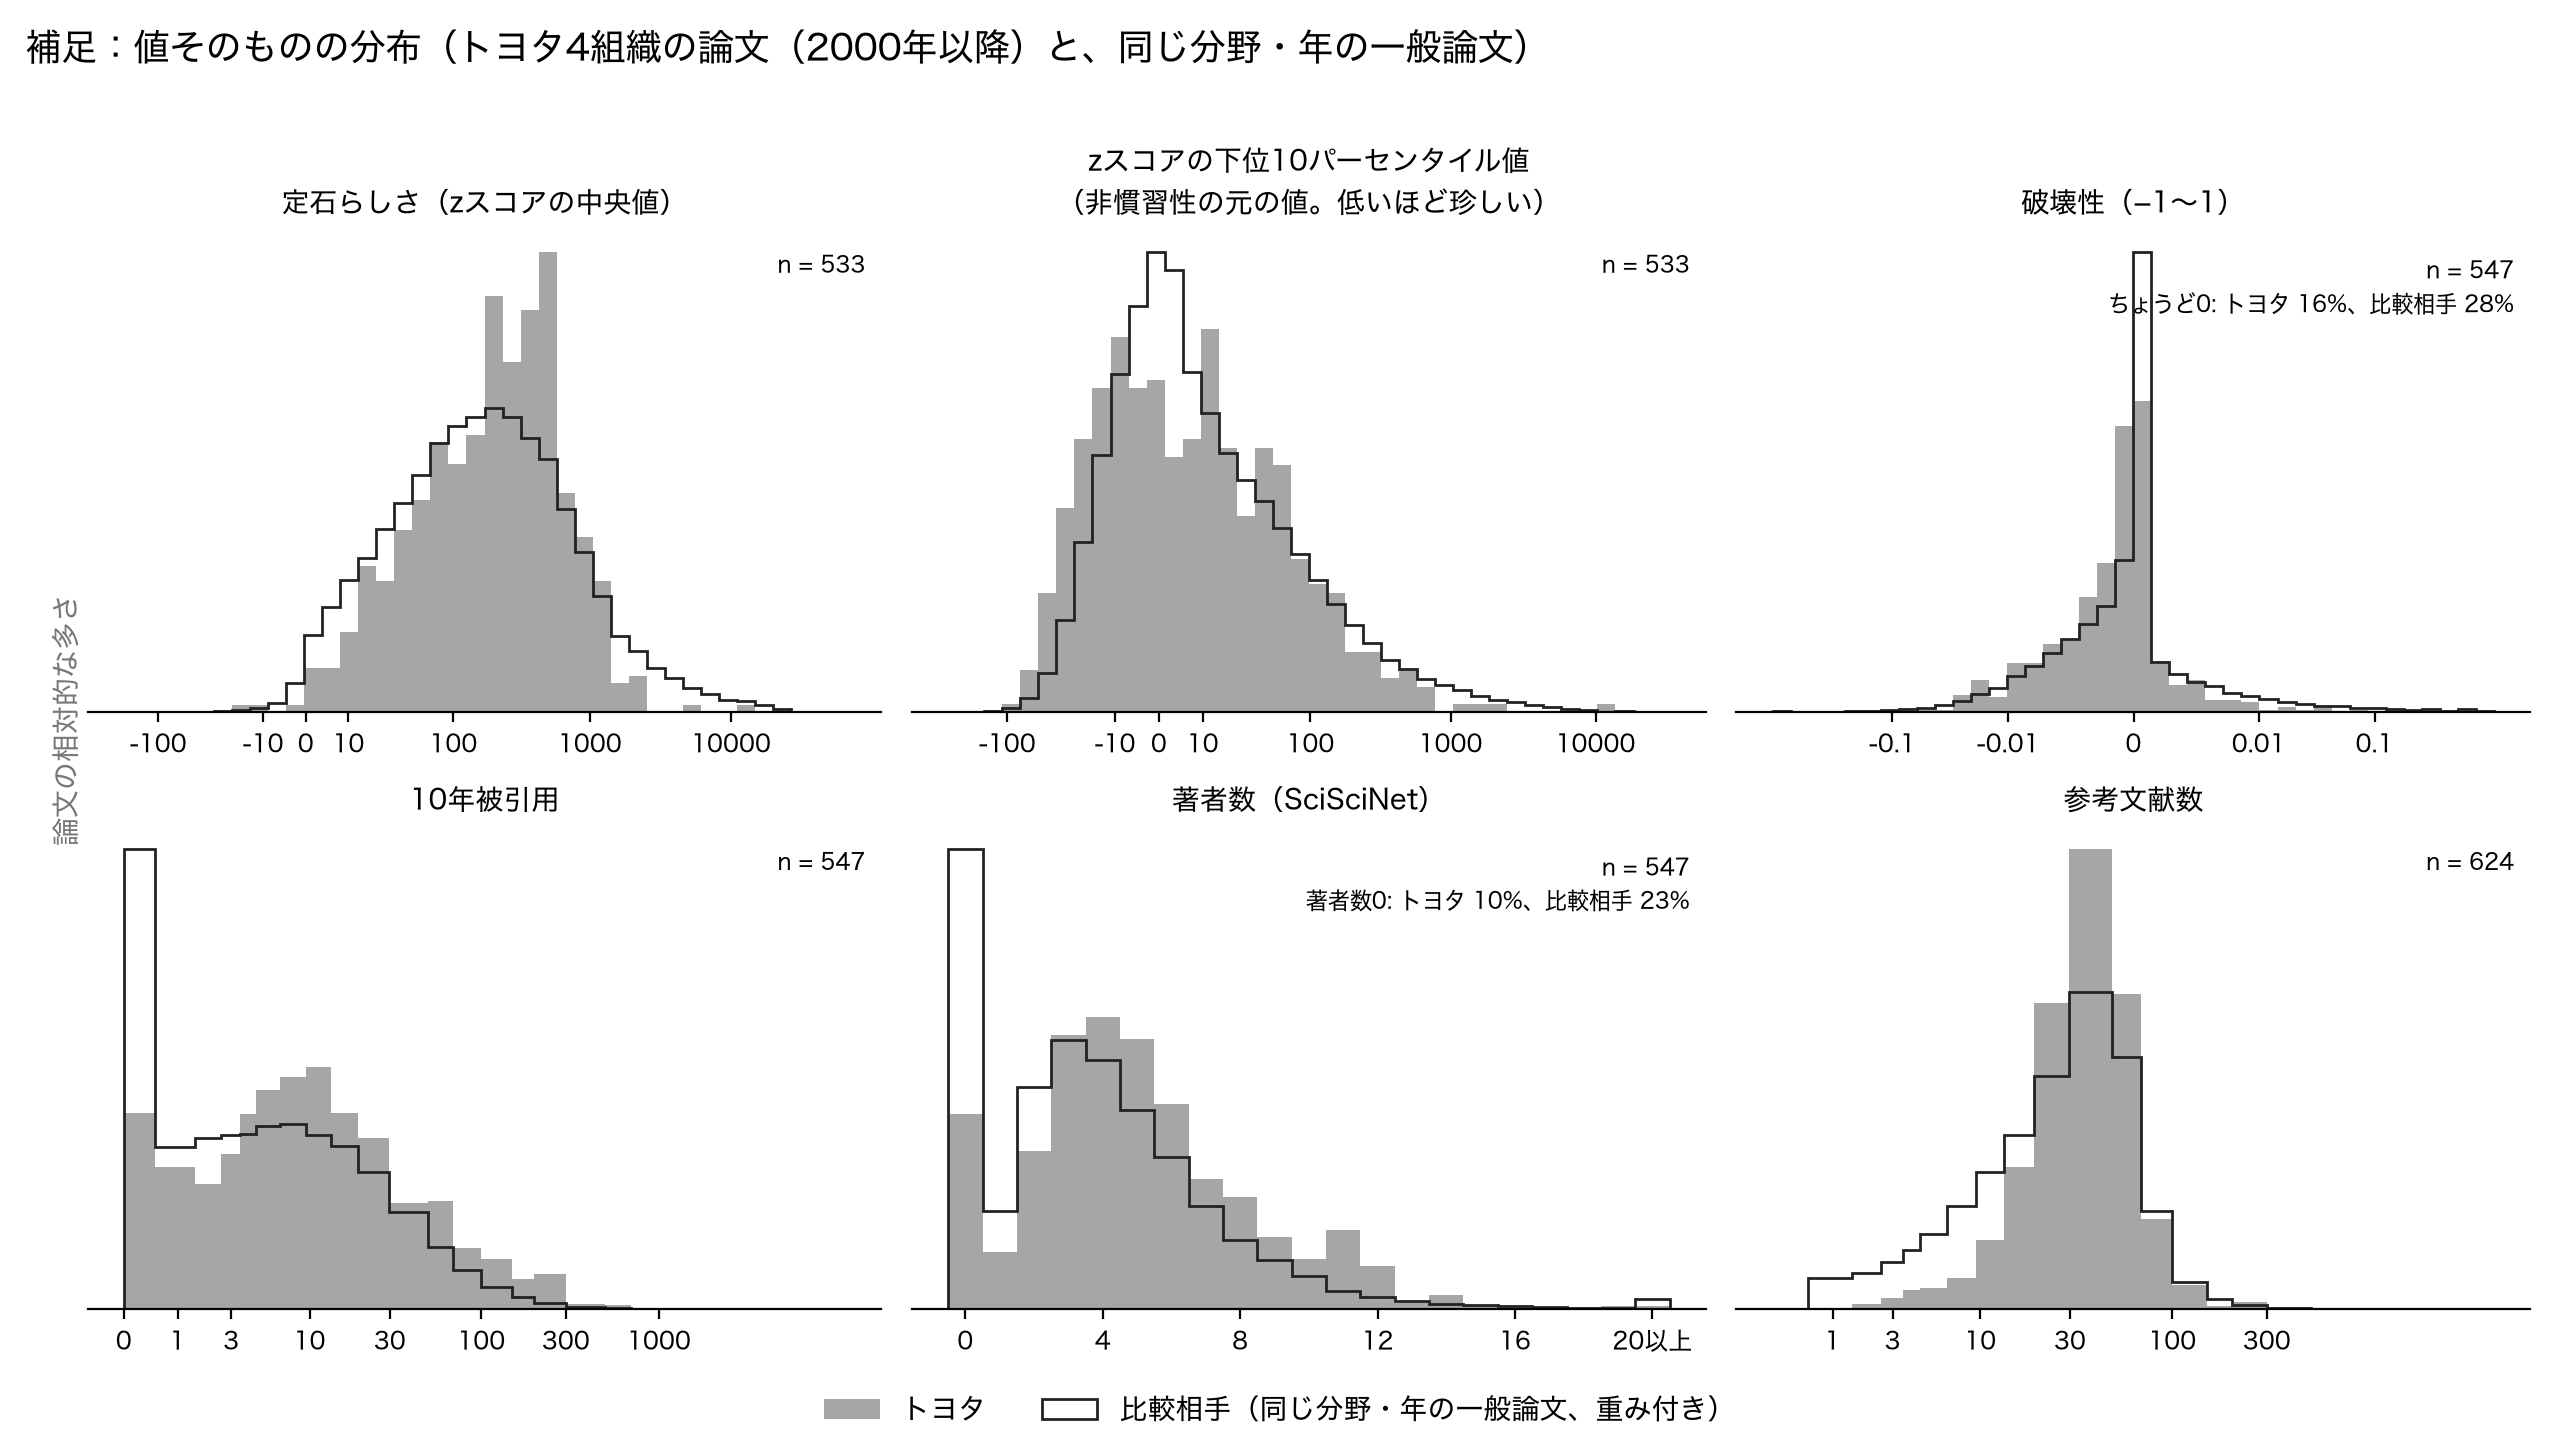

In [5]:
def weighted_base(g: pd.DataFrame, col: str):
    # 比較相手の値と重みを返す。重みは分野・年ごとに「トヨタの件数 ÷ 比較相手の件数」。
    # 値が欠けている論文は、トヨタ側・比較相手側ともに数えない。
    t = g.dropna(subset=[col]).groupby(["field_id", "year"]).size().rename("n_t")
    b = base.dropna(subset=[col]).merge(t, left_on=["field_id", "year"], right_index=True, how="inner")
    n_b = b.groupby(["field_id", "year"])[col].transform("size")
    return b[col].to_numpy(), (b["n_t"] / n_b).to_numpy()


def symlog(x, lin):
    # 符号を保ったまま対数的に縮める。|x| が lin までは線形に近く、それより大きいと対数になる
    x = np.asarray(x, dtype=float)
    return np.sign(x) * np.log10(1 + np.abs(x) / lin)


def log1(x):
    return np.log10(1 + np.asarray(x, dtype=float))


def cap20(x):
    return np.minimum(np.asarray(x, dtype=float), 20)


# (列, 図に書く名前, 横軸の変換, 目盛りに書く元の値)
VALUES = [
    ("ss_conventionality", "定石らしさ（zスコアの中央値）", lambda x: symlog(x, 10), [-100, -10, 0, 10, 100, 1000, 10000]),
    ("ss_novelty", "zスコアの下位10パーセンタイル値\n（非慣習性の元の値。低いほど珍しい）", lambda x: symlog(x, 10), [-100, -10, 0, 10, 100, 1000, 10000]),
    ("ss_disruption", "破壊性（−1〜1）", lambda x: symlog(x, 0.001), [-0.1, -0.01, 0, 0.01, 0.1]),
    ("ss_c10", "10年被引用", log1, [0, 1, 3, 10, 30, 100, 300, 1000]),
    ("ss_team_size", "著者数（SciSciNet）", cap20, [0, 4, 8, 12, 16, 20]),
    ("n_refs", "参考文献数", log1, [1, 3, 10, 30, 100, 300]),
]


def value_panel(ax, g: pd.DataFrame, col: str, label: str, tr, ticks, nbins: int = 40):
    raw_t = g[col].dropna().to_numpy()
    tv = tr(raw_t)
    bv, w = weighted_base(g, col)
    bt = tr(bv)
    if col == "ss_team_size":
        edges = np.arange(-0.5, 21.5, 1)  # 著者数は1人刻み
    elif col in ("ss_c10", "n_refs"):
        # 件数は整数なので、小さい値は1件刻み、大きい値はおおむね対数で等間隔の区間にする（区間の境目は整数の間）
        cuts = np.array([1, 2, 3, 4, 5, 7, 10, 14, 20, 30, 50, 70, 100, 150, 200, 300, 500, 700, 1000, 1500, 2000, 3000])
        raw_max = max(raw_t.max(), bv.max())
        raw_edges = np.concatenate([[0], cuts[cuts - 0.5 < raw_max] - 0.5, [raw_max + 0.5]])  # 0 の区間は 0〜0.5
        edges = tr(raw_edges)
    else:
        lo, hi = min(tv.min(), bt.min()), max(tv.max(), bt.max())
        edges = np.linspace(lo, hi, nbins + 1)
    ax.hist(tv, bins=edges, density=True, color=GRAY, label="トヨタ")
    # 比較相手は重み付きで、面積が 1 になるように描く
    ax.hist(bt, bins=edges, weights=w, density=True, histtype="step", color=INK, lw=1.0,
            label="比較相手（同じ分野・年の一般論文、重み付き）")
    ax.set_xticks(tr(np.array(ticks, dtype=float)))
    ax.set_xticklabels([("20以上" if col == "ss_team_size" and t == 20 else f"{t:g}") for t in ticks], fontsize=8.5)
    ax.set_yticks([])
    ax.set_title(label, fontsize=10)
    for s in ("top", "right", "left"):
        ax.spines[s].set_visible(False)
    note = f"n = {len(tv)}"
    if col in ("ss_disruption", "ss_team_size"):
        z_t = float((raw_t == 0).mean() * 100)
        z_b = float(np.average(bv == 0, weights=w) * 100)
        note += f"\n{'ちょうど0' if col == 'ss_disruption' else '著者数0'}: トヨタ {z_t:.0f}%、比較相手 {z_b:.0f}%"
    ax.text(0.98, 0.95, note, transform=ax.transAxes, ha="right", va="top", fontsize=8)


fig, axes = plt.subplots(2, 3, figsize=(12.8, 7.2), dpi=200)
for ax, (col, label, tr, ticks) in zip(axes.flat, VALUES):
    value_panel(ax, d, col, label, tr, ticks)
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=2, frameon=False, bbox_to_anchor=(0.5, -0.005))
fig.supylabel("論文の相対的な多さ", fontsize=10, color=DIM)
fig.suptitle("補足：値そのものの分布（トヨタ4組織の論文（2000年以降）と、同じ分野・年の一般論文）", fontsize=13, x=0.01, ha="left")
fig.tight_layout(rect=(0, 0.04, 1, 0.97))
fig.savefig(FIG / "fig_supp_values.png", facecolor="white")
plt.close(fig)
display(Image(str(FIG / "fig_supp_values.png"), width=1000))


## 資料の数字との照合

図1〜3 に書いた中央値が、報告資料（2026-09-28）の7ページ・8ページ・11ページの表の数字と一致することを確かめる。資料の数字は `docs/slides/numbers_progress_2026-09.json`。


In [6]:
key = {"非慣習性": "nov", "定石らしさ": "conv", "破壊性": "dis", "10年被引用": "c10"}
stage_key = {"分野・年のみ": "fy", "分野・年＋参考文献数": "ref", "分野・年＋チーム規模": "team", "分野・年＋両方": "both"}

def col_name(s: str) -> str:
    return s.split(" ")[0]  # 「非慣習性 （高いほど…）」→「非慣習性」

# 図1（7ページ）
for _, r in summ1.iterrows():
    want = N["stages"][stage_key[r["行"]]][key[col_name(r["列"])]]
    assert abs(r["中央値"] - want) < 0.05, (r["行"], r["列"], r["中央値"], want)
# 図2（8ページ）
org_res = {ORGS[x["org"]]: x for x in N["org_res"]}
org_res["トヨタ全体"] = N["stages"]["both"]
for _, r in summ2.iterrows():
    want = org_res[r["行"]][key[col_name(r["列"])]]
    assert abs(r["中央値"] - want) < 0.05, (r["行"], r["列"], r["中央値"], want)
# 図3（11ページ）
team_res = {x["t"]: x for x in N["team_strata"]}
for _, r in summ3.iterrows():
    want = team_res[r["行"]][stage_key[r["列"]]]
    assert abs(r["中央値"] - want) < 0.05, (r["行"], r["列"], r["中央値"], want)
    if r["列"] == "分野・年のみ":
        assert r["n"] == team_res[r["行"]]["n"], (r["行"], r["n"], team_res[r["行"]]["n"])
print("資料7ページ・8ページ・11ページの表の中央値と一致")
summary.pivot_table(index=["図", "行"], columns="列", values="中央値", sort=False)


資料7ページ・8ページ・11ページの表の中央値と一致


列                           非慣習性 （高いほど珍しい組み合わせ）  定石らしさ （高いほど定石の組み合わせ）  \
図           行                                                           
図1（資料7ページ）  分野・年のみ                         54.1                  54.5   
            分野・年＋参考文献数                     52.6                  56.0   
            分野・年＋チーム規模                     53.7                  55.2   
            分野・年＋両方                        52.8                  56.5   
図2（資料8ページ）  豊田中央研究所                        63.3                  56.6   
            未来創生センター                       59.2                  48.0   
            AISIN IMRA（日本）                 41.6                  51.3   
            AISIN IMRA（米国）                 35.9                  64.0   
            トヨタ全体                          52.8                  56.5   
図3（資料11ページ） 1〜2人                            NaN                   NaN   
            3〜4人                            NaN                   NaN   
            5〜6人                            NaN                   NaN   
            7人以上                            NaN                   NaN   

列                           破壊性 （高いほど流れを断ち切る）  10年被引用 （高いほど多く引用）  分野・年のみ  \
図           行                                                              
図1（資料7ページ）  分野・年のみ                       40.0               65.1     NaN   
            分野・年＋参考文献数                   49.5               59.0     NaN   
            分野・年＋チーム規模                   49.6               52.3     NaN   
            分野・年＋両方                      50.2               50.8     NaN   
図2（資料8ページ）  豊田中央研究所                      50.1               50.8     NaN   
            未来創生センター                     52.0               48.3     NaN   
            AISIN IMRA（日本）               53.0               44.0     NaN   
            AISIN IMRA（米国）               48.4               79.7     NaN   
            トヨタ全体                        50.2               50.8     NaN   
図3（資料11ページ） 1〜2人                          NaN                NaN    44.4   
            3〜4人                          NaN                NaN    40.2   
            5〜6人                          NaN                NaN    32.8   
            7人以上                          NaN                NaN    31.7   

列                           分野・年＋参考文献数  分野・年＋チーム規模  分野・年＋両方  
図           行                                                
図1（資料7ページ）  分野・年のみ                 NaN         NaN      NaN  
            分野・年＋参考文献数             NaN         NaN      NaN  
            分野・年＋チーム規模             NaN         NaN      NaN  
            分野・年＋両方                NaN         NaN      NaN  
図2（資料8ページ）  豊田中央研究所                NaN         NaN      NaN  
            未来創生センター               NaN         NaN      NaN  
            AISIN IMRA（日本）         NaN         NaN      NaN  
            AISIN IMRA（米国）         NaN         NaN      NaN  
            トヨタ全体                  NaN         NaN      NaN  
図3（資料11ページ） 1〜2人                  60.3        46.5     58.4  
            3〜4人                  51.1        48.9     52.7  
            5〜6人                  43.0        45.7     50.2  
            7人以上                  36.7        44.6     47.5